In [2]:
# ============================================================
# CELL 1 — Libraries & Data Load
# ============================================================
import warnings
warnings.filterwarnings("ignore")
import io, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, grangercausalitytests
from statsmodels.tsa.vector_ar.var_model import VAR

df = pd.read_excel(r"C:\Users\agast\Desktop\BA project\Combined final data.xlsx", engine="openpyxl")
df_clean = df.dropna()

cols = ['Brent Crude Oil Return %',
        'Nifty Auto Return %',
        'Nifty IT Return %',
        'Nifty FMCG Return %',
        'Nifty Pharma Return %',
        'Nifty Oil and Gas Return %',
        'Nifty Realty Return %']

data = df_clean[cols].dropna()
data = data.reset_index(drop=True)  # FIX
target_sectors = [c for c in cols if 'Nifty' in c]
print(f"Data loaded. Shape: {data.shape}")

Data loaded. Shape: (96, 7)


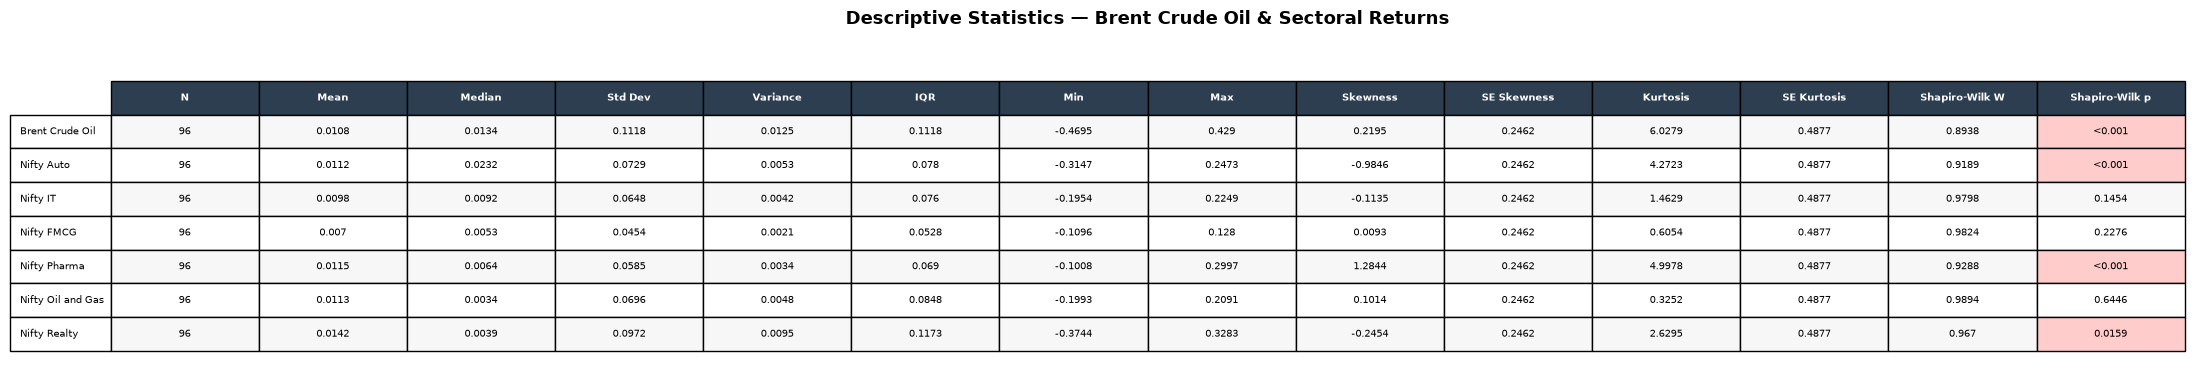

In [3]:
# ============================================================
# CELL 2 — Descriptive Statistics
# ============================================================
rows = []
for col in cols:
    s = data[col]
    n = s.count()
    sw_stat, sw_p = stats.shapiro(s)
    se_skew = np.sqrt(6 * n * (n-1) / ((n-2) * (n+1) * (n+3)))
    se_kurt = 2 * se_skew * np.sqrt((n*n-1) / ((n-3) * (n+5)))
    rows.append({
        'Series': col.replace(' Return %', ''),
        'N': n,
        'Mean': round(s.mean(), 4),
        'Median': round(s.median(), 4),
        'Std Dev': round(s.std(), 4),
        'Variance': round(s.var(), 4),
        'IQR': round(s.quantile(0.75) - s.quantile(0.25), 4),
        'Min': round(s.min(), 4),
        'Max': round(s.max(), 4),
        'Skewness': round(s.skew(), 4),
        'SE Skewness': round(se_skew, 4),
        'Kurtosis': round(s.kurt(), 4),
        'SE Kurtosis': round(se_kurt, 4),
        'Shapiro-Wilk W': round(sw_stat, 4),
        'Shapiro-Wilk p': '<0.001' if sw_p < 0.001 else round(sw_p, 4)
    })

desc_df = pd.DataFrame(rows).set_index('Series')

fig, ax = plt.subplots(figsize=(22, 4))
ax.axis('off')
table = ax.table(cellText=desc_df.values, colLabels=desc_df.columns,
                 rowLabels=desc_df.index, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(7.5)
table.scale(1.2, 1.9)
for j in range(len(desc_df.columns)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(len(desc_df.index)):
    color = '#f7f7f7' if i % 2 == 0 else 'white'
    for j in range(len(desc_df.columns)):
        table[i+1, j].set_facecolor(color)
sw_col_idx = list(desc_df.columns).index('Shapiro-Wilk p')
for i, val in enumerate(desc_df['Shapiro-Wilk p']):
    if val == '<0.001' or (isinstance(val, float) and val < 0.05):
        table[i+1, sw_col_idx].set_facecolor('#ffcccc')
plt.title("Descriptive Statistics — Brent Crude Oil & Sectoral Returns",
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

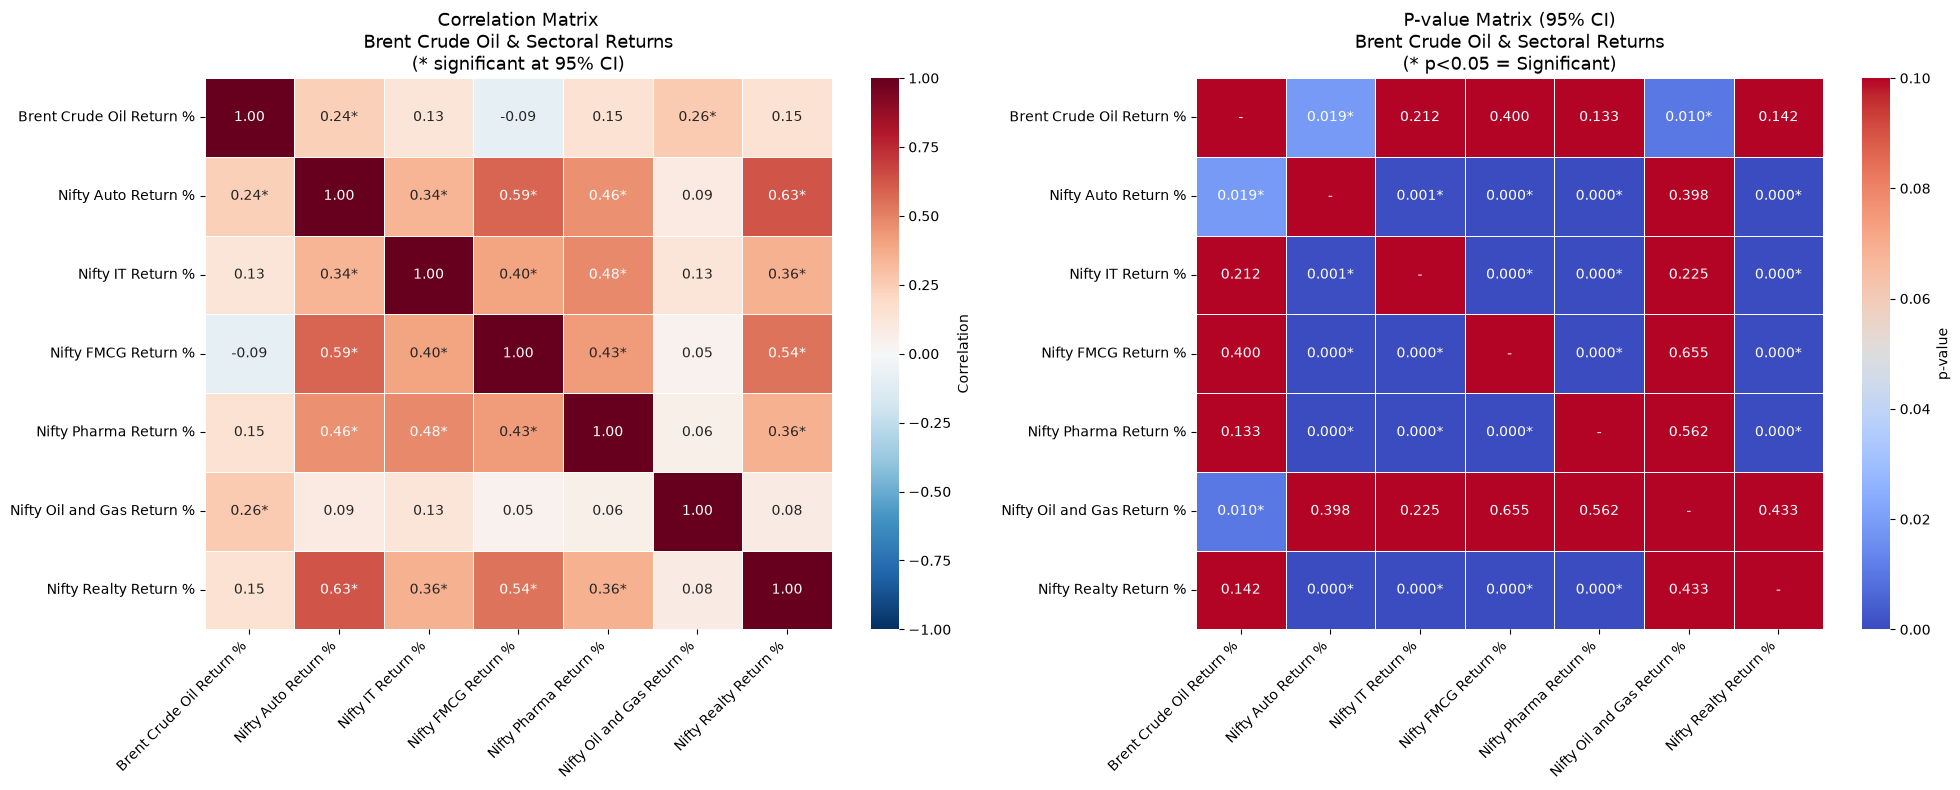

In [5]:
# ============================================================
# CELL 3 — Correlation Matrix
# ============================================================
corr_matrix = data.corr()
p_matrix = pd.DataFrame(np.ones((len(cols), len(cols))),
                         columns=cols, index=cols)
for i in cols:
    for j in cols:
        if i != j:
            _, p = stats.pearsonr(data[i], data[j])
            p_matrix.loc[i, j] = p

annot_matrix = pd.DataFrame('', index=cols, columns=cols)
sig_annot = pd.DataFrame('', index=cols, columns=cols)
for i in cols:
    for j in cols:
        r = corr_matrix.loc[i, j]
        p = p_matrix.loc[i, j]
        if i == j:
            annot_matrix.loc[i, j] = '1.00'
            sig_annot.loc[i, j] = '-'
        else:
            stars = '*' if p < 0.05 else ''
            annot_matrix.loc[i, j] = f'{r:.2f}{stars}'
            sig_annot.loc[i, j] = f'{p:.3f}{"*" if p < 0.05 else ""}'

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(corr_matrix, annot=annot_matrix, fmt='',
            cmap='RdBu_r', linewidths=0.5, vmin=-1, vmax=1,
            cbar_kws={'label': 'Correlation'}, ax=axes[0])
axes[0].set_title("Correlation Matrix\nBrent Crude Oil & Sectoral Returns\n(* significant at 95% CI)", fontsize=13)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)
sns.heatmap(p_matrix, annot=sig_annot, fmt='',
            cmap='coolwarm', linewidths=0.5, vmin=0, vmax=0.1,
            cbar_kws={'label': 'p-value'}, ax=axes[1])
axes[1].set_title("P-value Matrix (95% CI)\nBrent Crude Oil & Sectoral Returns\n(* p<0.05 = Significant)", fontsize=13)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_yticklabels(axes[1].get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

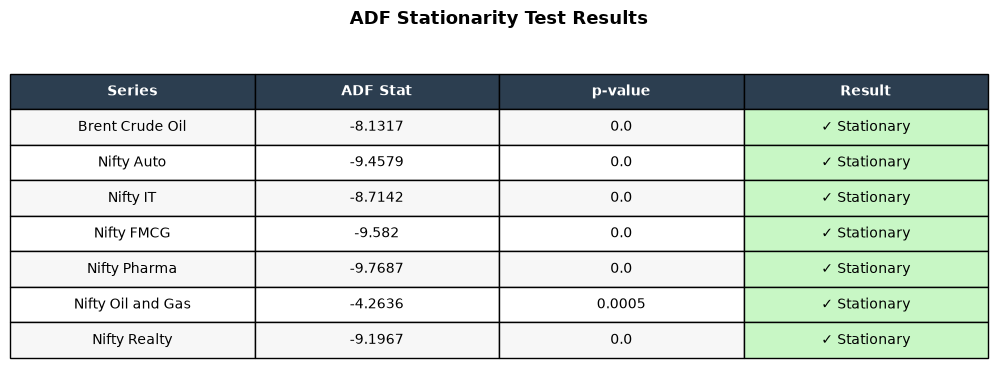

In [7]:
# ============================================================
# CELL 4 — ADF Test
# ============================================================
adf_store = []
for col in cols:
    result = adfuller(data[col].dropna())
    adf_store.append({
        'Series': col.replace(' Return %', ''),
        'ADF Stat': round(result[0], 4),
        'p-value': round(result[1], 4),
        'Result': "✓ Stationary" if result[1] < 0.05 else "✗ Non-stationary"
    })

adf_df = pd.DataFrame(adf_store)

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('off')
table = ax.table(cellText=adf_df.values, colLabels=adf_df.columns,
                 cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2.0)
for j in range(len(adf_df.columns)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(len(adf_df)):
    color = '#f7f7f7' if i % 2 == 0 else 'white'
    for j in range(len(adf_df.columns)):
        table[i+1, j].set_facecolor(color)
    if '✓' in adf_df.iloc[i]['Result']:
        table[i+1, 3].set_facecolor('#c8f7c5')
plt.title("ADF Stationarity Test Results", fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()



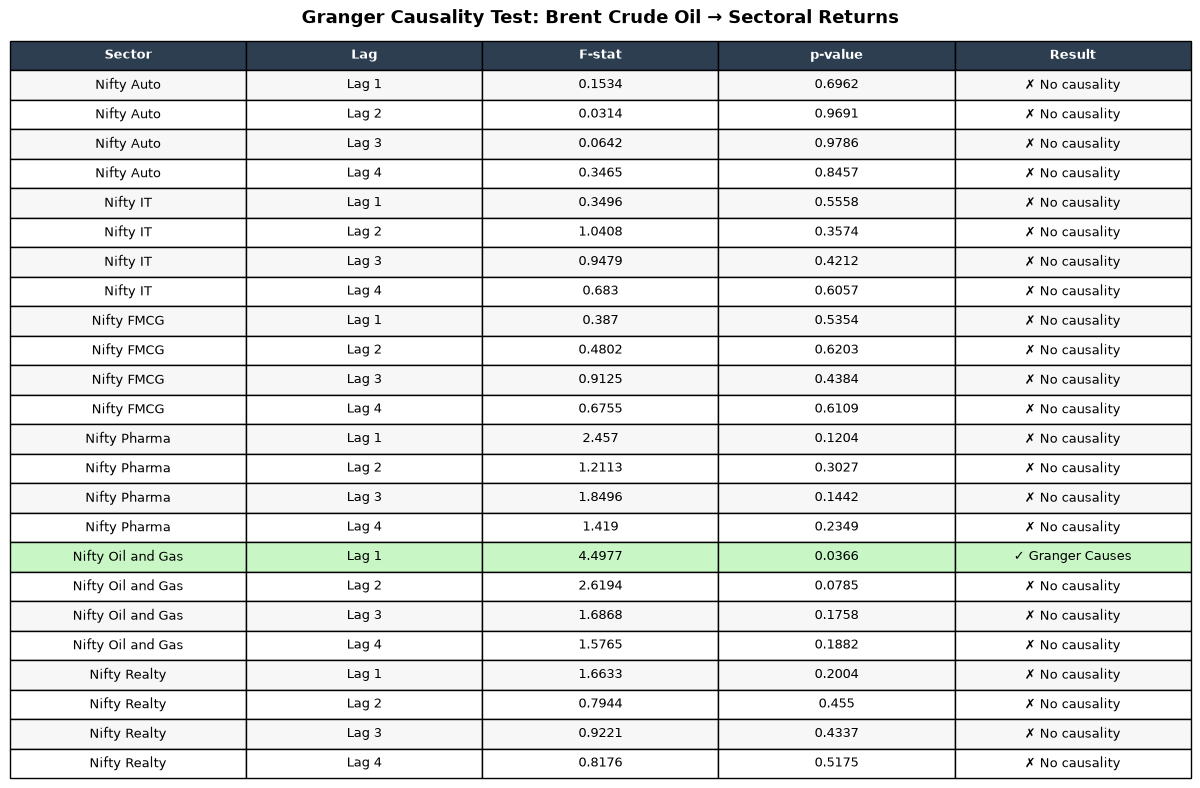

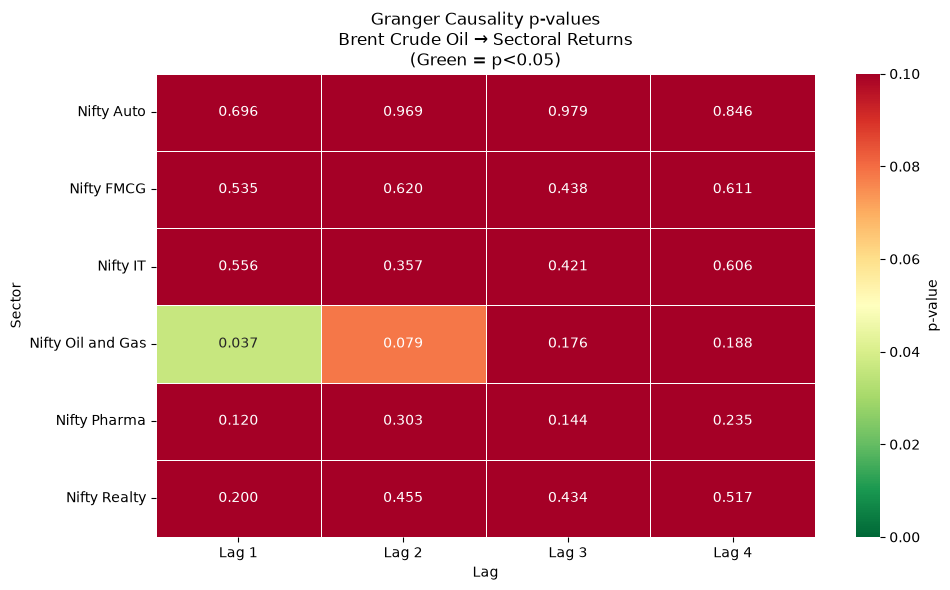

In [9]:
# ============================================================
# CELL 5 — Granger Causality
# ============================================================
max_lag = 4
results_store = []

for sector in target_sectors:
    granger_data = data[[sector, 'Brent Crude Oil Return %']]
    old_stdout = sys.stdout
    sys.stdout = io.StringIO()
    results = grangercausalitytests(granger_data, maxlag=max_lag)
    sys.stdout = old_stdout
    for lag in range(1, max_lag + 1):
        f_stat = results[lag][0]['ssr_ftest'][0]
        p_val  = results[lag][0]['ssr_ftest'][1]
        sig    = "✓ Granger Causes" if p_val < 0.05 else "✗ No causality"
        results_store.append({
            'Sector': sector.replace(' Return %', ''),
            'Lag': f'Lag {lag}',
            'F-stat': round(f_stat, 4),
            'p-value': round(p_val, 4),
            'Result': sig
        })

results_df = pd.DataFrame(results_store)

# Table
fig, ax = plt.subplots(figsize=(12, 8))
ax.axis('off')
table = ax.table(cellText=results_df.values, colLabels=results_df.columns,
                 cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.8)
for j in range(len(results_df.columns)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(len(results_df)):
    color = '#f7f7f7' if i % 2 == 0 else 'white'
    for j in range(len(results_df.columns)):
        table[i+1, j].set_facecolor(color)
    if results_df.iloc[i]['Result'] == '✓ Granger Causes':
        for j in range(len(results_df.columns)):
            table[i+1, j].set_facecolor('#c8f7c5')
plt.title("Granger Causality Test: Brent Crude Oil → Sectoral Returns",
          fontsize=13, fontweight='bold', pad=60)
plt.tight_layout()
plt.show()

# Heatmap
granger_pivot = results_df.pivot(index='Sector', columns='Lag', values='p-value')
plt.figure(figsize=(10, 6))
sns.heatmap(granger_pivot, annot=True, fmt=".3f", cmap="RdYlGn_r",
            linewidths=0.5, vmin=0, vmax=0.1,
            cbar_kws={'label': 'p-value'})
plt.title("Granger Causality p-values\nBrent Crude Oil → Sectoral Returns\n(Green = p<0.05)")
plt.xlabel("Lag")
plt.ylabel("Sector")
plt.tight_layout()
plt.show()

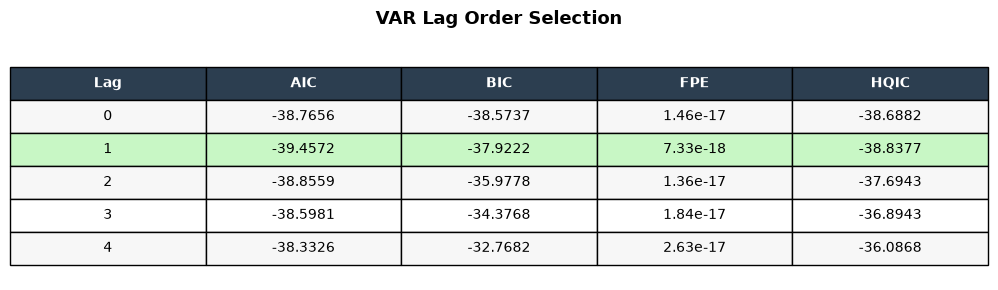

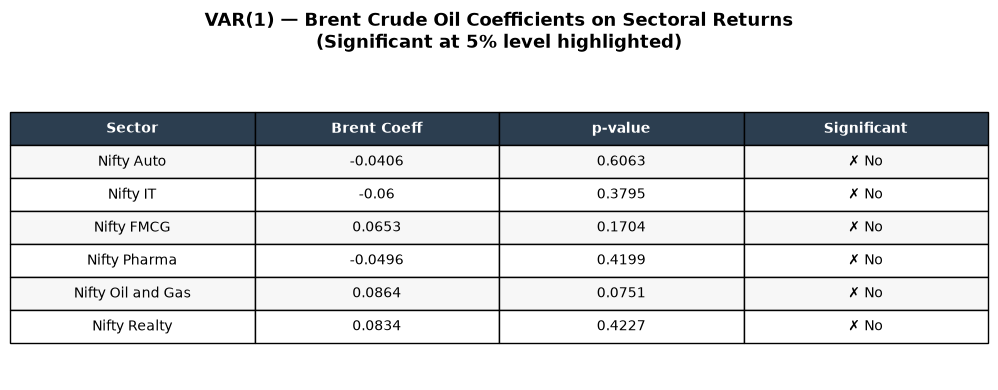

In [11]:
# ============================================================
# CELL 6 — VAR Model
# ============================================================
var_data = data.copy()
var_data.index = range(len(var_data))

model = VAR(var_data)
nobs = len(var_data)
neqs = var_data.shape[1]
max_lag_var = int((nobs - neqs) / neqs)

# Lag Selection Table
lag_selection = model.select_order(maxlags=min(4, max_lag_var))
n_lags = min(4, max_lag_var) + 1

lag_df = pd.DataFrame({
    'Lag': range(n_lags),
    'AIC': [round(lag_selection.ics['aic'][i], 4) for i in range(n_lags)],
    'BIC': [round(lag_selection.ics['bic'][i], 4) for i in range(n_lags)],
    'FPE': [f"{lag_selection.ics['fpe'][i]:.2e}" for i in range(n_lags)],
    'HQIC': [round(lag_selection.ics['hqic'][i], 4) for i in range(n_lags)]
})

fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')
table = ax.table(cellText=lag_df.values, colLabels=lag_df.columns,
                 cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2.0)
for j in range(len(lag_df.columns)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(len(lag_df)):
    color = '#f7f7f7' if i % 2 == 0 else 'white'
    for j in range(len(lag_df.columns)):
        table[i+1, j].set_facecolor(color)
# Highlight Lag 1 row
for j in range(len(lag_df.columns)):
    table[2, j].set_facecolor('#c8f7c5')
plt.title("VAR Lag Order Selection", fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Fit VAR
var_model = model.fit(1)

# VAR Coefficients Table — Brent only
coef_store = []
for sector in target_sectors:
    eq = var_model.params[sector]
    pval = var_model.pvalues[sector]
    coef_store.append({
        'Sector': sector.replace(' Return %', ''),
        'Brent Coeff': round(eq['L1.Brent Crude Oil Return %'], 4),
        'p-value': round(pval['L1.Brent Crude Oil Return %'], 4),
        'Significant': '✓ Yes' if pval['L1.Brent Crude Oil Return %'] < 0.05 else '✗ No'
    })

coef_df = pd.DataFrame(coef_store)

fig, ax = plt.subplots(figsize=(10, 4))
ax.axis('off')
table = ax.table(cellText=coef_df.values, colLabels=coef_df.columns,
                 cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2.0)
for j in range(len(coef_df.columns)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')
for i in range(len(coef_df)):
    color = '#f7f7f7' if i % 2 == 0 else 'white'
    for j in range(len(coef_df.columns)):
        table[i+1, j].set_facecolor(color)
    if '✓' in coef_df.iloc[i]['Significant']:
        for j in range(len(coef_df.columns)):
            table[i+1, j].set_facecolor('#c8f7c5')
plt.title("VAR(1) — Brent Crude Oil Coefficients on Sectoral Returns\n(Significant at 5% level highlighted)",
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()


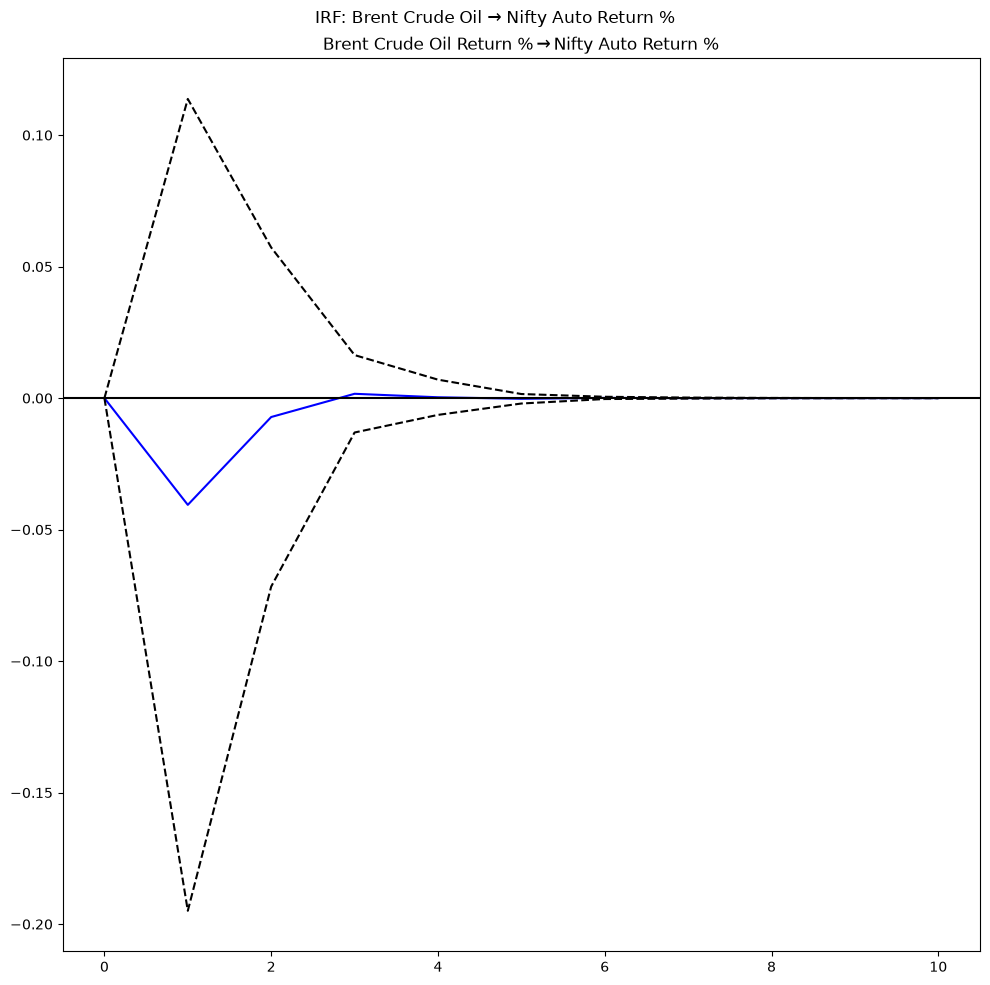

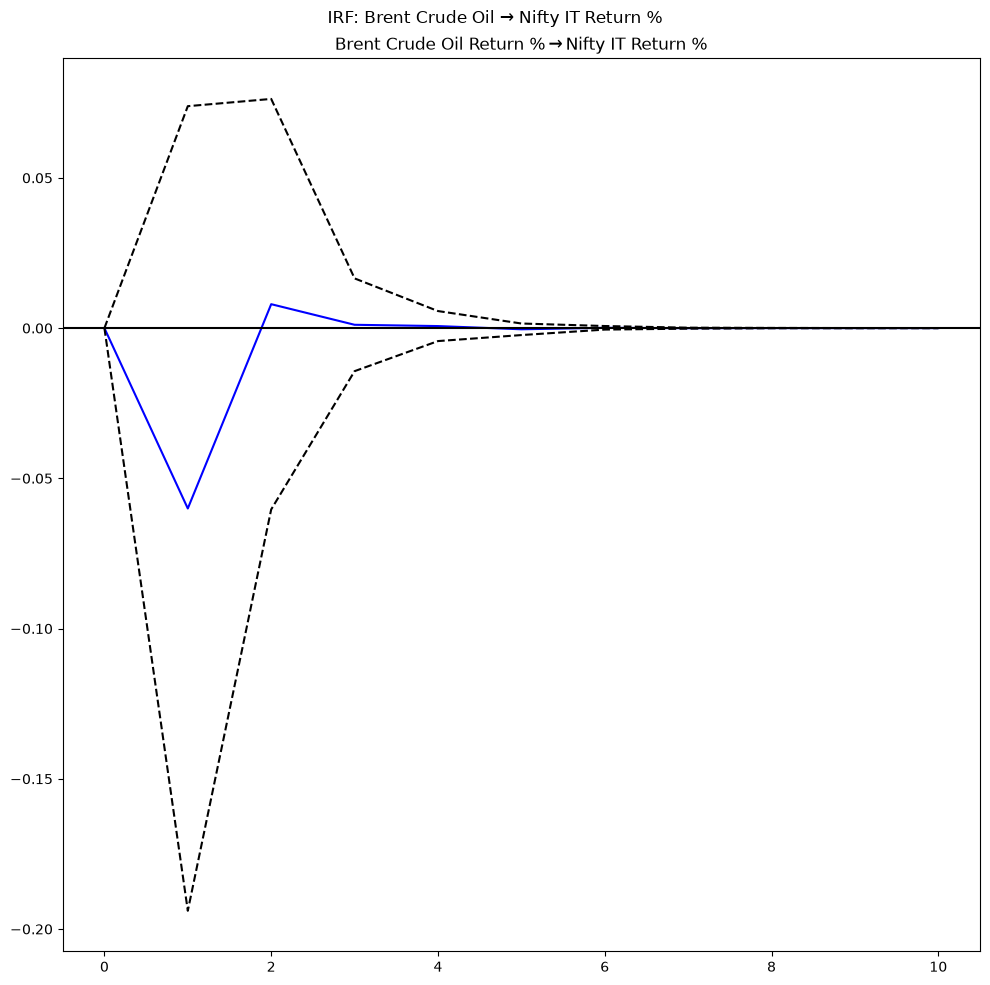

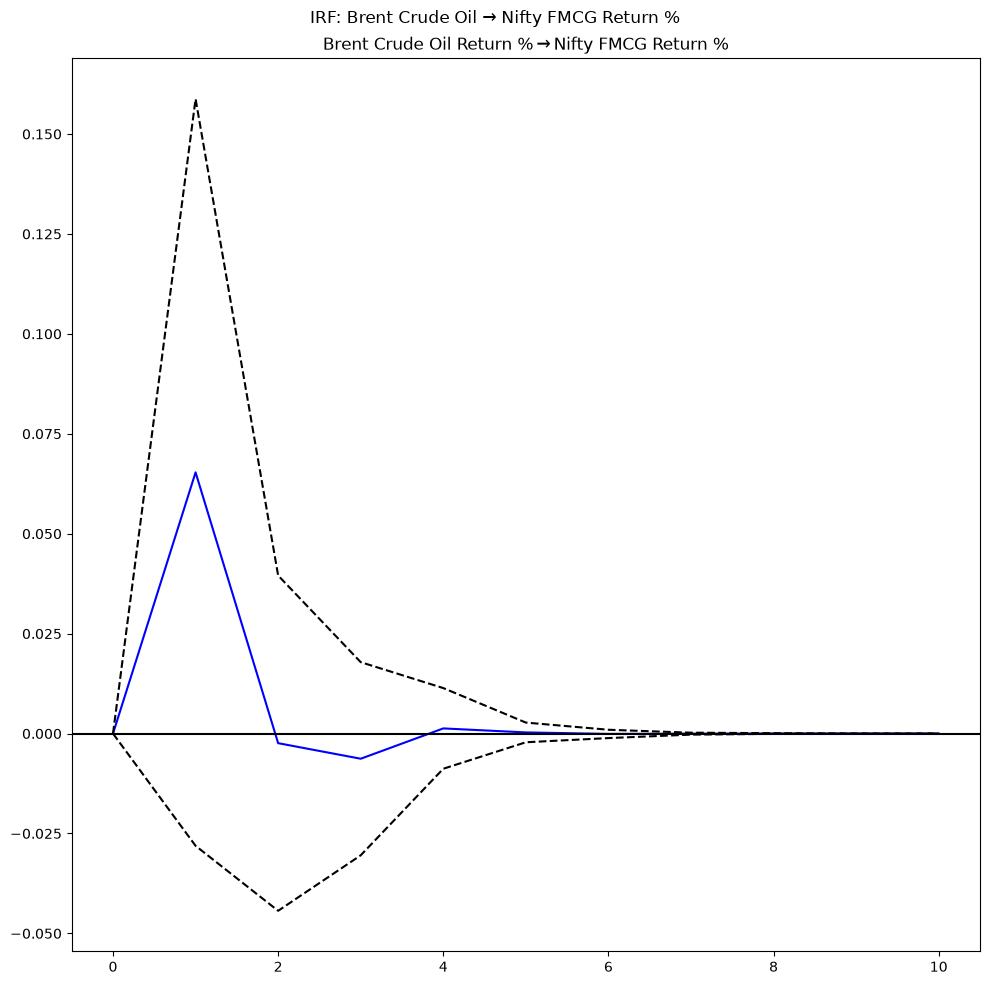

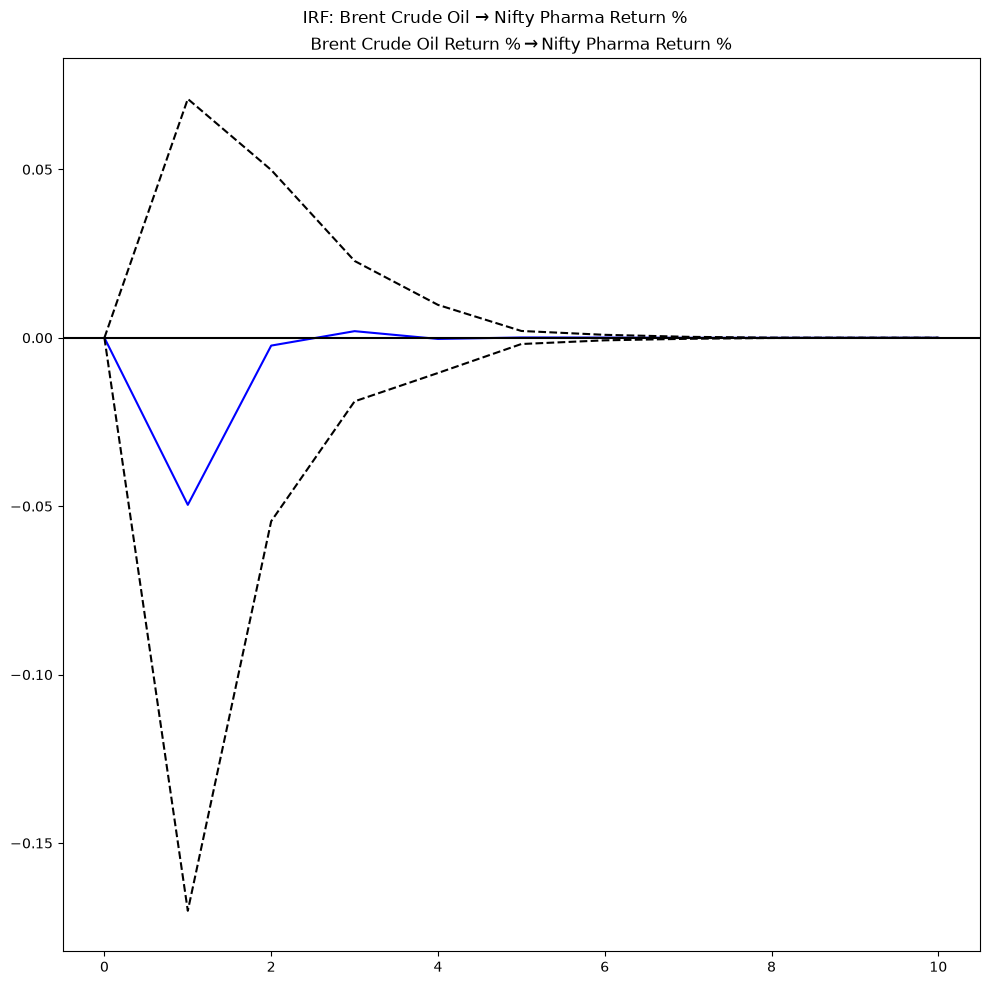

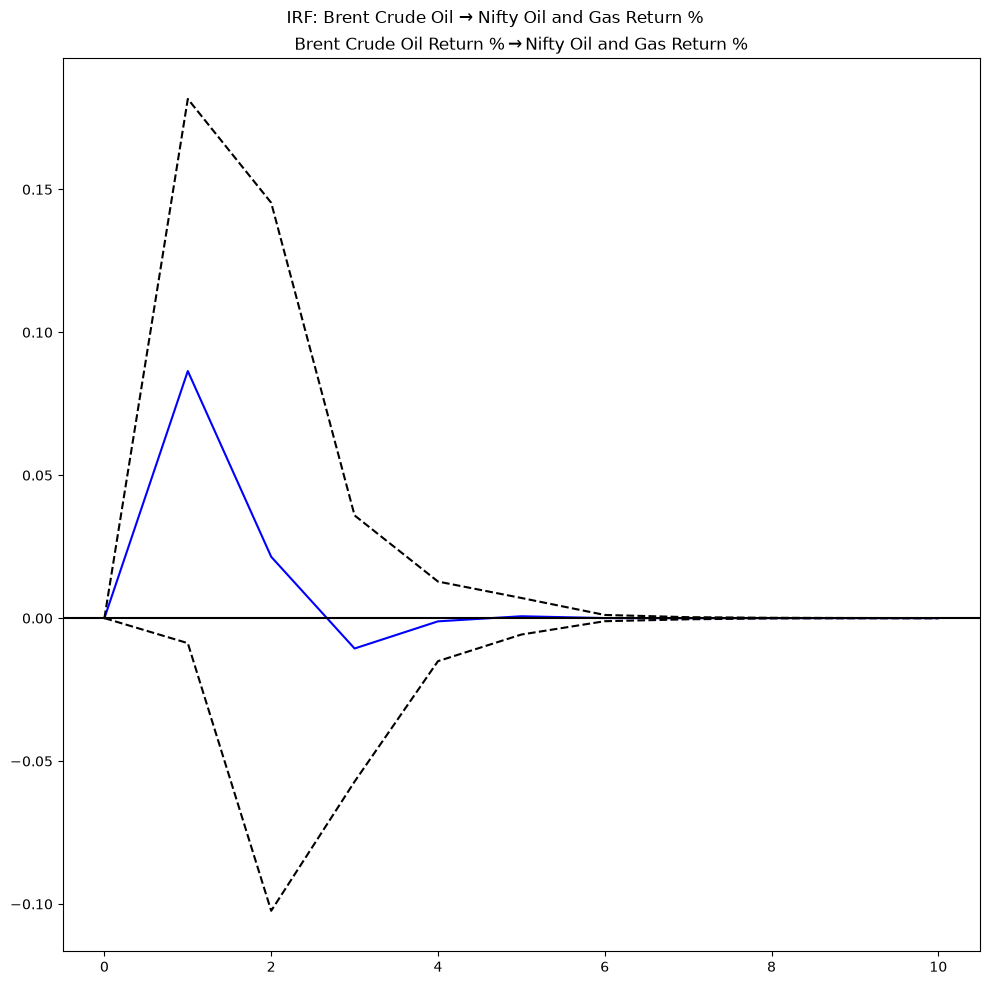

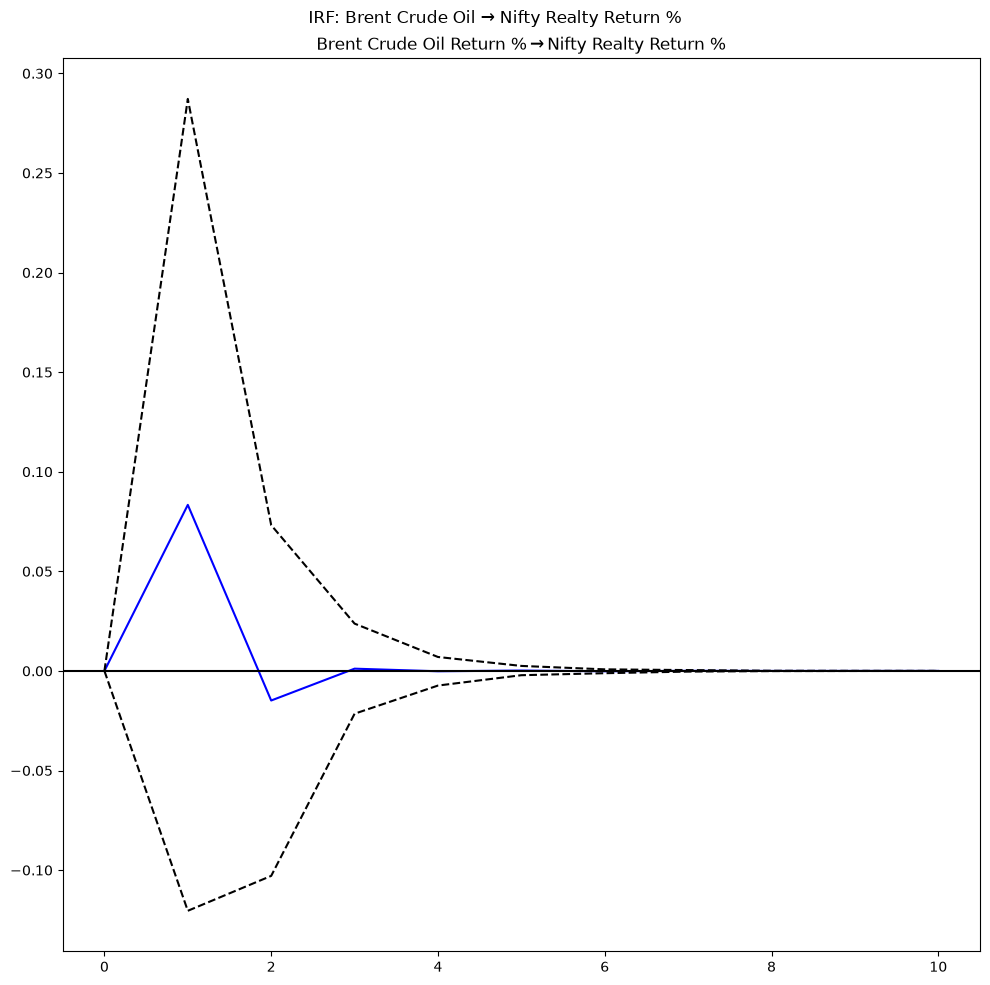

In [13]:
# ============================================================
# CELL 7 — IRF
# ============================================================
irf = var_model.irf(10)

for sector in target_sectors:
    irf.plot(impulse='Brent Crude Oil Return %', response=sector)
    plt.suptitle(f'IRF: Brent Crude Oil → {sector}', fontsize=12)
    plt.tight_layout()
    plt.show()

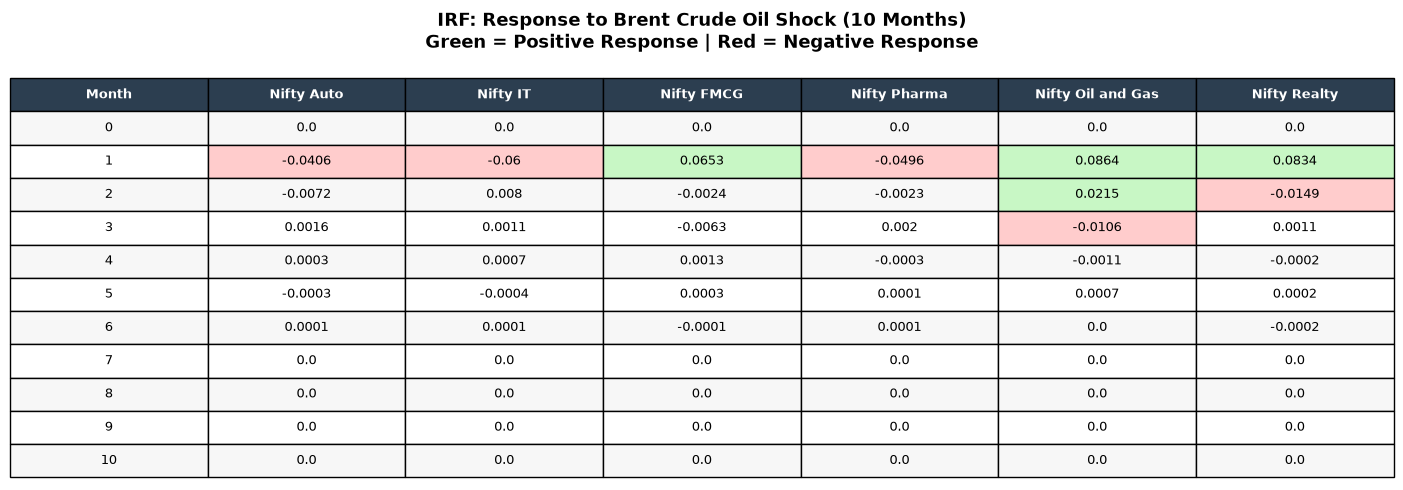

In [25]:
# ============================================================
# CELL 7 — IRF Table
# ============================================================
irf = var_model.irf(10)
irf_data = irf.irfs

brent_idx = list(var_data.columns).index('Brent Crude Oil Return %')
sector_cols = [s.replace(' Return %', '') for s in target_sectors]

rows = []
for month in range(11):
    row = [str(month)]  # string se float nahi banega
    for sector in target_sectors:
        sec_idx = list(var_data.columns).index(sector)
        val = round(float(irf_data[month, sec_idx, brent_idx]), 4)
        if abs(val) < 0.00005:
            val = 0.0
        row.append(val)
    rows.append(row)

irf_df = pd.DataFrame(rows, columns=['Month'] + sector_cols)

fig, ax = plt.subplots(figsize=(14, 5))
ax.axis('off')
table = ax.table(cellText=irf_df.values,
                 colLabels=irf_df.columns,
                 cellLoc='center',
                 loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.9)

for j in range(len(irf_df.columns)):
    table[0, j].set_facecolor('#2c3e50')
    table[0, j].set_text_props(color='white', fontweight='bold')

for i in range(len(irf_df)):
    color = '#f7f7f7' if i % 2 == 0 else 'white'
    for j in range(len(irf_df.columns)):
        table[i+1, j].set_facecolor(color)
        if j > 0:
            try:
                val = float(irf_df.iloc[i, j])
                if val > 0.01:
                    table[i+1, j].set_facecolor('#c8f7c5')
                elif val < -0.01:
                    table[i+1, j].set_facecolor('#ffcccc')
            except:
                pass

plt.title("IRF: Response to Brent Crude Oil Shock (10 Months)\nGreen = Positive Response | Red = Negative Response",
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()